# Convolutional neural networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/cnn/cnn-notebook.ipynb)

Companion notebook for the *Convolutional neural networks* slides. Each idea is written first by hand
with NumPy, in small classes shaped like PyTorch's, and then with the PyTorch module that does the same job.

**Data:** the Digits data (1 797 handwritten digits, each a grid of 8 × 8 gray pixels).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch import nn

RANDOM_STATE = 42
TRAINING_STEPS = 100

torch.manual_seed(RANDOM_STATE)
torch.set_default_dtype(torch.float64)
rng = np.random.default_rng(RANDOM_STATE)

digits = load_digits()
images = digits.images / 16
image = images[0][None]  # one channel: shape (C, H, W) = (1, 8, 8), the layout PyTorch uses
image_t = torch.tensor(image)
print("image shape:", image.shape)

image shape: (1, 8, 8)


## 1. The convolution

Place the $k \times k$ kernel with its corner at row $i$, column $j$, multiply, add up and add the bias:
$Z_{ij} = \sum_{m=0}^{k-1} \sum_{n=0}^{k-1} X_{i+m,\,j+n} \, K_{mn} + b$.
The NumPy `Conv2d` below has the same arguments as `nn.Conv2d` and keeps the kernels in `weight`,
shaped (filters, channels, $k$, $k$). It already handles channels, padding and stride, used in the next sections.
This kernel adds the left column of each patch and subtracts the right one: it finds vertical edges.

In [2]:
class Conv2d:
    """Slide each kernel over one image of shape (C, H, W), like nn.Conv2d."""

    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, stride: int = 1, padding: int = 0):
        self.weight = rng.normal(size=(out_channels, in_channels, kernel_size, kernel_size))
        self.bias = np.zeros(out_channels)
        self.stride, self.padding = stride, padding

    def __call__(self, X: np.ndarray) -> np.ndarray:
        p, s, k = self.padding, self.stride, self.weight.shape[-1]
        X = np.pad(X, ((0, 0), (p, p), (p, p)))
        n_out = ((X.shape[1] - k) // s + 1, (X.shape[2] - k) // s + 1)
        Z = np.zeros((len(self.weight), *n_out))
        for i, j in np.ndindex(n_out):
            patch = X[:, i * s:i * s + k, j * s:j * s + k]
            Z[:, i, j] = np.sum(self.weight * patch, axis=(1, 2, 3)) + self.bias
        return Z


def copy_weights(mine: Conv2d, theirs: nn.Conv2d) -> None:
    """Put the NumPy kernels and biases into the torch layer."""
    with torch.no_grad():
        theirs.weight.copy_(torch.from_numpy(mine.weight))
        theirs.bias.copy_(torch.from_numpy(mine.bias))


vertical_edge = np.array([[1.0, 0, -1], [1, 0, -1], [1, 0, -1]])
conv = Conv2d(1, 1, kernel_size=3)
conv.weight = vertical_edge[None, None]
feature_map = conv(image)

torch_conv = nn.Conv2d(1, 1, kernel_size=3)
copy_weights(conv, torch_conv)
print("feature map shape:", feature_map.shape)
print("same result:", np.allclose(feature_map, torch_conv(image_t).detach().numpy()))

feature map shape: (1, 6, 6)
same result: True


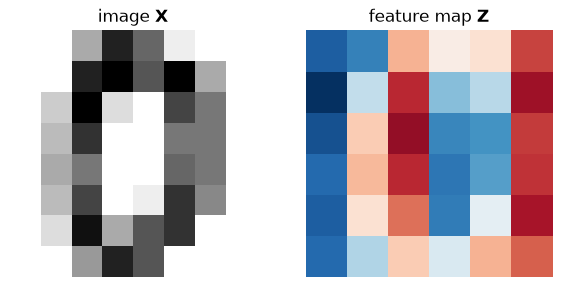

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(image[0], cmap="gray_r")
axes[0].set_title("image $\\mathbf{X}$")
limit = np.abs(feature_map).max()
axes[1].imshow(feature_map[0], cmap="RdBu_r", vmin=-limit, vmax=limit)
axes[1].set_title("feature map $\\mathbf{Z}$")
for ax in axes:
    ax.axis("off")
plt.show()

## 2. Padding and stride

Padding $p$ adds a border of zeros; stride $s$ is how far the kernel jumps.
The output side is $n_{\text{out}} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1$.
Besides the layer `nn.Conv2d`, PyTorch has the plain function `F.conv2d`, which takes the kernel as an argument.

In [4]:
def output_size(n: int, k: int, p: int, s: int) -> int:
    return (n + 2 * p - k) // s + 1


kernel_t = torch.tensor(vertical_edge[None, None])
for p, s in [(1, 1), (0, 2)]:
    conv = Conv2d(1, 1, kernel_size=3, stride=s, padding=p)
    conv.weight = vertical_edge[None, None]
    by_hand = conv(image)
    torch_result = F.conv2d(image_t, kernel_t, stride=s, padding=p)
    print(f"p = {p}, s = {s}: shape {by_hand.shape[1:]}, formula {output_size(8, 3, p, s)}",
          "| same result:", np.allclose(by_hand, torch_result.numpy()))

p = 1, s = 1: shape (8, 8), formula 8 | same result: True
p = 0, s = 2: shape (3, 3), formula 3 | same result: True


## 3. Channels, filters and ReLU

With $C$ channels each kernel is $k \times k \times C$ and sums over all of them:
$Z^{(f)}_{ij} = \sum_{c} \sum_{m} \sum_{n} X_{i+m,\,j+n,\,c} \, K^{(f)}_{mnc} + b^{(f)}$.
ReLU then keeps the positive entries: $A_{ij} = \max(0, Z_{ij})$.
Here three digits play the role of the three color channels.

In [5]:
color_image = images[:3]  # shape (C, H, W) = (3, 8, 8)
conv = Conv2d(3, 1, kernel_size=3)
conv.bias = np.array([0.5])
A = np.maximum(0, conv(color_image))

torch_layer = nn.Sequential(nn.Conv2d(3, 1, kernel_size=3), nn.ReLU())
copy_weights(conv, torch_layer[0])
print("same result:", np.allclose(A, torch_layer(torch.tensor(color_image)).detach().numpy()))
print(f"ReLU sets {np.mean(A == 0):.0%} of the entries to 0")
print("parameters of one filter, k*k*C + 1 =", conv.weight.size + conv.bias.size,
      "| torch counts", sum(p.numel() for p in torch_layer.parameters()))

same result: True
ReLU sets 6% of the entries to 0
parameters of one filter, k*k*C + 1 = 28 | torch counts 28


## 4. Pooling

Max pooling keeps the largest value of each $2 \times 2$ window (stride 2), so the map shrinks by half.
It has no weights to learn.

In [6]:
class MaxPool2d:
    """Largest value of each k x k window, stride k, like nn.MaxPool2d."""

    def __init__(self, kernel_size: int):
        self.kernel_size = kernel_size

    def __call__(self, A: np.ndarray) -> np.ndarray:
        C, H, W, k = *A.shape, self.kernel_size
        return A[:, :H // k * k, :W // k * k].reshape(C, H // k, k, W // k, k).max(axis=(2, 4))


pooled_by_hand = MaxPool2d(2)(A)
pooled_torch = nn.MaxPool2d(2)(torch.tensor(A))
print("shape", A.shape, "->", pooled_by_hand.shape, "| same result:", np.allclose(pooled_by_hand, pooled_torch.numpy()))

shape (1, 6, 6) -> (1, 3, 3) | same result: True


## 5. The gradient of a shared weight

Each kernel weight is used at every position, so its gradient adds up all of them:
$\dfrac{\partial L}{\partial K_{mn}} = \sum_i \sum_j \dfrac{\partial L}{\partial Z_{ij}} \, X_{i+m,\,j+n}$.
With the toy loss $L = \frac{1}{2}\sum_{ij} Z_{ij}^2$ we have $\partial L / \partial Z_{ij} = Z_{ij}$.
PyTorch's autograd finds the same gradient in `weight.grad` after `loss.backward()`.

In [7]:
conv = Conv2d(1, 1, kernel_size=3)
dL_dZ = conv(image)[0]
gradient_by_hand = np.array([[np.sum(dL_dZ * image[0, m:m + 6, n:n + 6]) for n in range(3)] for m in range(3)])

torch_conv = nn.Conv2d(1, 1, kernel_size=3)
copy_weights(conv, torch_conv)
loss = 0.5 * (torch_conv(image_t) ** 2).sum()
loss.backward()
print("same result:", np.allclose(gradient_by_hand, torch_conv.weight.grad[0, 0].numpy()))

same result: True


## 6. A small CNN

Convolution, ReLU and pooling, then a dense layer to the 10 digits, trained with `nn.CrossEntropyLoss` and `torch.optim.Adam`.
PyTorch layers work on a batch, so the images enter with shape (examples, channels, $H$, $W$).
Eight filters of size $3 \times 3$ with $p = 1$ keep the $8 \times 8$ size, and pooling halves it.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(images[:, None], digits.target, test_size=0.3,
                                                    random_state=RANDOM_STATE, stratify=digits.target)
X_train_t, X_test_t, y_train_t = torch.tensor(X_train), torch.tensor(X_test), torch.tensor(y_train)

side = output_size(8, 3, 1, 1) // 2
cnn = nn.Sequential(nn.Conv2d(1, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Flatten(), nn.Linear(8 * side * side, 10))
print("shape before the dense layer:", tuple(cnn[:3](X_test_t).shape[1:]), "| formula:", (8, side, side))

optimizer = torch.optim.Adam(cnn.parameters(), lr=0.01)
cross_entropy = nn.CrossEntropyLoss()
for _ in range(TRAINING_STEPS):
    optimizer.zero_grad()
    loss = cross_entropy(cnn(X_train_t), y_train_t)
    loss.backward()
    optimizer.step()

with torch.no_grad():
    predictions = cnn(X_test_t).argmax(dim=1).numpy()
print(f"training cost {loss.item():.3f}, test accuracy {np.mean(predictions == y_test):.3f}")

shape before the dense layer: (8, 4, 4) | formula: (8, 4, 4)


training cost 0.043, test accuracy 0.969


## Exercises

1. Use the horizontal-edge kernel (the transpose of `vertical_edge`) in section 1 and compare both feature maps.
2. Write an `AvgPool2d` class like `MaxPool2d` and compare it with `nn.AvgPool2d(2)`.
3. Count the parameters of a layer with 64 filters of size $3 \times 3$ on a color image (check with `nn.Conv2d(3, 64, 3)`),
   and of a dense layer from a $200 \times 200 \times 3$ image to 1 000 neurons.